# SongNet Reproduction: Convolutional Recurrent Neural Network (C-RNN)

UE24CS352A Machine Learning mini-project, reproducing *SongNet: Real-time Music Classification*
(Chen Chen, Chi Zhang, Yue Zhang).

This notebook trains the C-RNN on **log-mel spectrograms** computed from the FMA-small audio.
Unlike the baselines, it uses no FMA metadata features, only the audio. It uses the same
train/val/test track split and the same metrics as the MLP/SVM notebook.

Reference accuracy reported for the C-RNN: **65.23%** (paper) / **65.32%** (poster). These are the
paper's numbers, not results of this notebook.



## Architecture: what the paper specifies and what we inferred

| Component | Source |
|---|---|
| Mel-spectrogram input | Paper |
| 3 convolutional layers, each with batch normalization, ReLU and dropout | Paper / poster |
| Recurrent layers after the convolutional layers | Paper / poster |
| A genre prediction at every timestep, averaged over timesteps | Paper / poster |
| Spectrogram settings: 22,050 Hz, 2048-point FFT, hop 512, 128 mel bands, 30 s clips | **Inferred** (common defaults) |
| Conv channels 32 / 64 / 128, 3×3 kernels, max-pooling (2,2), (4,2), (4,2) | **Inferred** |
| Recurrent layer type GRU, 2 layers, 128 hidden units, unidirectional | **Inferred** |
| Dropout 0.3, timestep aggregation by averaging logits | **Inferred** |
| Adam (lr 1e-3, weight decay 1e-4), batch 32, ≤40 epochs, LR halving on plateau, early stopping | **Inferred** |

The paper does not give filter counts, kernel or pooling sizes, RNN size or training settings, so
this is **not** an exact replica of the original implementation. All inferred values are set in
the configuration cell below.

## 1. Setup

In [1]:
import random
import subprocess
import sys
import time
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from joblib import Parallel, delayed
from torch.utils.data import DataLoader, Dataset

### Shared split and metric code

This cell is **identical in all notebooks**. It defines the single train/val/test split and the
evaluation metrics, so the MLP, SVM and C-RNN are trained and scored on exactly the same tracks
in the same way.

In [2]:
import hashlib
import json

import seaborn as sns
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split

SEED = 42
SPLITS = ("train", "val", "test")
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.20, "test": 0.10}

# FMA-small MP3s that are empty or truncated (reported in the FMA repository issues).
# They are dropped before splitting so that every model sees the same tracks.
EXCLUDED_TRACK_IDS = (98565, 98567, 98569, 99134, 108925, 133297)


def load_small_subset(tracks_csv, exclude=EXCLUDED_TRACK_IDS):
    """FMA-small track IDs and their top-level genre, from tracks.csv."""
    tracks = pd.read_csv(tracks_csv, index_col=0, header=[0, 1])
    small = tracks[tracks[("set", "subset")] == "small"]
    df = pd.DataFrame({"track_id": small.index.astype(int),
                       "genre": small[("track", "genre_top")].values})
    if df["genre"].isna().any():
        raise ValueError("Some FMA-small tracks have no genre_top label.")
    df = df[~df["track_id"].isin(exclude)]
    return df.sort_values("track_id").reset_index(drop=True)


def create_splits(df, seed=SEED):
    """Stratified 70/20/10 split of track IDs."""
    X, y = df["track_id"].values, df["genre"].values
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=seed)
    X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=1/3, stratify=y_tmp, random_state=seed)
    parts = [pd.DataFrame({"track_id": ids, "genre": labels, "split": name})
             for name, ids, labels in (("train", X_tr, y_tr), ("val", X_val, y_val), ("test", X_te, y_te))]
    return pd.concat(parts, ignore_index=True).sort_values("track_id").reset_index(drop=True)


def validate_splits(splits, tolerance=0.01):
    """Raise if the manifest is malformed, overlapping or not a stratified 70/20/10 split."""
    if set(splits.columns) != {"track_id", "genre", "split"}:
        raise ValueError(f"Unexpected columns: {list(splits.columns)}")
    if splits["track_id"].duplicated().any():
        dupes = splits.loc[splits["track_id"].duplicated(), "track_id"].tolist()
        raise ValueError(f"Track IDs assigned more than once: {dupes[:10]}")
    unknown = set(splits["split"]) - set(SPLITS)
    if unknown:
        raise ValueError(f"Unknown split names: {unknown}")
    for name, frac in SPLIT_FRACTIONS.items():
        actual = (splits["split"] == name).mean()
        if abs(actual - frac) > tolerance:
            raise ValueError(f"{name} holds {actual:.3f} of tracks, expected {frac:.2f}")
    counts = pd.crosstab(splits["genre"], splits["split"])
    missing = [s for s in SPLITS if s not in counts.columns or (counts[s] == 0).any()]
    if missing:
        raise ValueError(f"Some genres are absent from split(s): {missing}")


def load_or_create_splits(tracks_csv, splits_path, overwrite=False):
    """Load splits.csv, creating it from tracks.csv only if it does not exist yet."""
    splits_path = Path(splits_path)
    if overwrite or not splits_path.exists():
        splits = create_splits(load_small_subset(tracks_csv))
        validate_splits(splits)
        splits_path.parent.mkdir(parents=True, exist_ok=True)
        splits.to_csv(splits_path, index=False)
        print(f"Created split manifest: {splits_path}")
    else:
        print(f"Loaded existing split manifest: {splits_path}")
    splits = pd.read_csv(splits_path, dtype={"track_id": int, "genre": str, "split": str})
    validate_splits(splits)
    return splits


def file_sha256(path):
    """Checksum of splits.csv; matching values in both notebooks mean they used the same split."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def audio_path(audio_dir, track_id):
    """Path of an FMA MP3, e.g. fma_small/000/000002.mp3."""
    tid = f"{int(track_id):06d}"
    return Path(audio_dir) / tid[:3] / f"{tid}.mp3"


def compute_metrics(y_true, y_pred, class_names):
    """Accuracy, macro precision/recall/F1, per-class report and confusion matrix."""
    labels = list(range(len(class_names)))
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
        "per_class": classification_report(y_true, y_pred, labels=labels, target_names=class_names,
                                           output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        "n_samples": int(len(y_true)),
    }


def plot_confusion_matrix(cm, class_names, title, save_path=None):
    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set(xlabel="Predicted genre", ylabel="True genre", title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150)
    return fig


def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2))

In [3]:
IN_COLAB = "google.colab" in sys.modules

USE_DRIVE = True  # saving splits.csv, results and models to Google Drive so they survive the session

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path("/content/drive/MyDrive/SongNet")
    else:
        PROJECT_ROOT = Path("/content/SongNet")
    FMA_DIR = Path("/content/fma")  # dataset on Colab's local disk (fast, re-downloaded each session)
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    FMA_DIR = PROJECT_ROOT / "data"

METADATA_DIR = FMA_DIR / "fma_metadata"
AUDIO_DIR = FMA_DIR / "fma_small"
SPLITS_PATH = PROJECT_ROOT / "data" / "splits.csv"
DOWNLOAD_IF_MISSING = IN_COLAB  # never downloads the dataset outside Colab

print("Outputs saved under:", PROJECT_ROOT)
print("FMA data dir:", FMA_DIR)

CACHE_DIR = Path("/content/mel_cache") if IN_COLAB else FMA_DIR / "mel_cache"
RESULTS_DIR = PROJECT_ROOT / "results" / "crnn"
MODELS_DIR = PROJECT_ROOT / "models"
for d in (CACHE_DIR, RESULTS_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive
Outputs saved under: /content/drive/MyDrive/SongNet
FMA data dir: /content/fma


In [4]:
# Spectrogram settings (inferred)
SR = 22_050
CLIP_SECONDS = 30.0
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128
MIN_AUDIO_SECONDS = 1.0  # shorter decoded audio is treated as a broken file

# Model settings (inferred)
CONV_CHANNELS = (32, 64, 128)
POOL_SIZES = ((2, 2), (4, 2), (4, 2))  # (frequency, time)
RNN_HIDDEN = 128
RNN_LAYERS = 2
DROPOUT = 0.3

# Training settings (inferred)
BATCH_SIZE = 32
EPOCHS = 40
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
LR_PATIENCE = 3
EARLY_STOP_PATIENCE = 8
NUM_WORKERS = 2 if IN_COLAB else 0


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
USE_AMP = device.type == "cuda"
print("Device:", device, "| torch", torch.__version__, "| librosa", librosa.__version__)

Device: cuda | torch 2.11.0+cu130 | librosa 0.11.0


## 2. Get FMA-small audio and metadata

`tracks.csv` (from `fma_metadata.zip`) is needed only if `data/splits.csv` does not exist yet.
`fma_small.zip` contains the 8,000 MP3 clips.

In [5]:
FMA_URL = "https://os.unil.cloud.switch.ch/fma"


def download_and_extract(archive, members=()):
    """Download an FMA archive into FMA_DIR and unzip it (optionally only some members)."""
    FMA_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = FMA_DIR / f"{archive}.zip"
    print(f"Downloading {archive}.zip ...")
    subprocess.run(["wget", "-nv", "-O", str(zip_path), f"{FMA_URL}/{archive}.zip"], check=True)
    print(f"Extracting {archive}.zip ...")
    subprocess.run(["unzip", "-q", "-o", str(zip_path), *members, "-d", str(FMA_DIR)], check=True)
    zip_path.unlink()


if not (METADATA_DIR / "tracks.csv").exists() and not SPLITS_PATH.exists():
    if not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError(f"Place tracks.csv in {METADATA_DIR}")
    download_and_extract("fma_metadata", ["fma_metadata/tracks.csv"])
if not AUDIO_DIR.exists():
    if not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError(f"Place the FMA-small audio in {AUDIO_DIR}")
    download_and_extract("fma_small")
print("Audio dir:", AUDIO_DIR)

Extracting fma_small.zip ...
Audio dir: /content/fma/fma_small


## 3. Shared train / validation / test split

All models use **one** split manifest, `data/splits.csv`, created by the shared code in Section 1:

- FMA-small tracks (`tracks.csv`, `set.subset == "small"`), labelled by `track.genre_top`.
- Six MP3s known to be empty or truncated are removed first (`EXCLUDED_TRACK_IDS`) so that the
  baseline models and the C-RNN see exactly the same tracks.
- Stratified 70% / 20% / 10% split with `random_state=42`.

The manifest is only generated if it does not already exist; otherwise it is loaded. Because the
split code and seed are identical in both notebooks, it comes out the same even if each notebook
creates it separately. Both notebooks print its SHA-256 checksum and store it in their saved
metrics, so you can confirm they used the identical split.

In [6]:
splits = load_or_create_splits(METADATA_DIR / "tracks.csv", SPLITS_PATH)
SPLITS_SHA256 = file_sha256(SPLITS_PATH)
CLASS_NAMES = sorted(splits["genre"].unique())  # list index = integer label
label_of = {g: i for i, g in enumerate(CLASS_NAMES)}

print(f"{len(splits)} tracks | splits.csv sha256 = {SPLITS_SHA256}")
pd.crosstab(splits["genre"], splits["split"], margins=True)[["train", "val", "test", "All"]]

Loaded existing split manifest: /content/drive/MyDrive/SongNet/data/splits.csv
7994 tracks | splits.csv sha256 = 77644b5972a1c9ec8dea69199f6660ddf8c4bd030183453140b5424b31aba57f


split,train,val,test,All
genre,,,,
Electronic,699,200,100,999
Experimental,699,200,100,999
Folk,700,200,100,1000
Hip-Hop,698,199,100,997
Instrumental,700,200,100,1000
International,700,200,100,1000
Pop,700,200,100,1000
Rock,699,200,100,999
All,5595,1599,800,7994


In [7]:
missing_audio = [t for t in splits["track_id"] if not audio_path(AUDIO_DIR, t).exists()]
if missing_audio:
    raise FileNotFoundError(f"{len(missing_audio)} manifest tracks have no MP3, e.g. {missing_audio[:5]}")
print("All", len(splits), "manifest tracks have an MP3 file.")

All 7994 manifest tracks have an MP3 file.


## 4. Mel-spectrogram extraction

For every track in the manifest: we load the MP3 as mono at 22,050 Hz, crop or zero-pad to exactly
30 s, compute a 128-band mel power spectrogram and convert it to decibels.

Spectrograms are cached as one `float16` array (`tracks × mels × frames`) in `CACHE_DIR`, in
manifest order. Extraction runs in parallel and resumes where it stopped if the session is
interrupted.

If any file cannot be decoded, the notebook stops rather than silently dropping it, because that
would make the C-RNN's test set differ from the baselines'.

In [8]:
N_SAMPLES = int(SR * CLIP_SECONDS)


def extract_mel(path):
    y, _ = librosa.load(path, sr=SR, mono=True, duration=CLIP_SECONDS)
    if len(y) < MIN_AUDIO_SECONDS * SR:
        raise ValueError(f"only {len(y) / SR:.2f}s of audio decoded")
    y = librosa.util.fix_length(y, size=N_SAMPLES)
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    return librosa.power_to_db(mel, ref=1.0, top_db=80.0).astype(np.float16)


def safe_extract(track_id):
    try:
        return track_id, extract_mel(audio_path(AUDIO_DIR, track_id)), None
    except Exception as e:
        return track_id, None, f"{type(e).__name__}: {e}"


track_ids = splits["track_id"].to_numpy()
N_FRAMES = librosa.feature.melspectrogram(
    y=np.zeros(N_SAMPLES, dtype=np.float32), sr=SR, n_fft=N_FFT,
    hop_length=HOP_LENGTH, n_mels=N_MELS).shape[1]

tag = f"mel_sr{SR}_fft{N_FFT}_hop{HOP_LENGTH}_mels{N_MELS}_{int(CLIP_SECONDS)}s"
MEL_PATH, IDS_PATH, DONE_PATH = (CACHE_DIR / f"{tag}{s}.npy" for s in ("", "_ids", "_done"))

if MEL_PATH.exists() and IDS_PATH.exists() and np.array_equal(np.load(IDS_PATH), track_ids):
    mels = np.load(MEL_PATH, mmap_mode="r+")
    done = np.load(DONE_PATH)
else:
    mels = np.lib.format.open_memmap(MEL_PATH, mode="w+", dtype=np.float16,
                                     shape=(len(track_ids), N_MELS, N_FRAMES))
    done = np.zeros(len(track_ids), dtype=bool)
    np.save(IDS_PATH, track_ids)
    np.save(DONE_PATH, done)

todo = np.flatnonzero(~done)
print(f"Spectrogram shape per track: ({N_MELS}, {N_FRAMES}) | {len(todo)} of {len(track_ids)} still to compute")

failures, start, CHUNK = {}, time.time(), 256
for i in range(0, len(todo), CHUNK):
    rows = todo[i:i + CHUNK]
    results = Parallel(n_jobs=-1)(delayed(safe_extract)(track_ids[r]) for r in rows)
    for r, (tid, mel, err) in zip(rows, results):
        if err is None:
            mels[r] = mel
            done[r] = True
        else:
            failures[int(tid)] = err
    mels.flush()
    np.save(DONE_PATH, done)
    print(f"  {min(i + CHUNK, len(todo))}/{len(todo)} done ({time.time() - start:.0f}s)")

if failures:
    pd.Series(failures, name="error").to_csv(RESULTS_DIR / "failed_tracks.csv")
    raise RuntimeError(
        f"{len(failures)} tracks could not be decoded: {failures}. Add their IDs to "
        "EXCLUDED_TRACK_IDS in the shared code cell of BOTH notebooks, delete data/splits.csv "
        "and re-run both notebooks so all models keep using identical tracks.")
assert done.all()
del mels
print("All spectrograms cached at", MEL_PATH)

Spectrogram shape per track: (128, 1292) | 7994 of 7994 still to compute
  256/7994 done (31s)
  512/7994 done (58s)
  768/7994 done (84s)
  1024/7994 done (109s)
  1280/7994 done (136s)
  1536/7994 done (163s)
  1792/7994 done (190s)
  2048/7994 done (216s)
  2304/7994 done (242s)
  2560/7994 done (268s)
  2816/7994 done (295s)
  3072/7994 done (320s)
  3328/7994 done (346s)
  3584/7994 done (373s)
  3840/7994 done (401s)
  4096/7994 done (427s)
  4352/7994 done (453s)
  4608/7994 done (480s)
  4864/7994 done (508s)
  5120/7994 done (532s)
  5376/7994 done (559s)
  5632/7994 done (586s)
  5888/7994 done (613s)
  6144/7994 done (640s)
  6400/7994 done (666s)
  6656/7994 done (693s)
  6912/7994 done (721s)
  7168/7994 done (748s)
  7424/7994 done (774s)
  7680/7994 done (800s)
  7936/7994 done (828s)
  7994/7994 done (833s)
All spectrograms cached at /content/mel_cache/mel_sr22050_fft2048_hop512_mels128_30s.npy


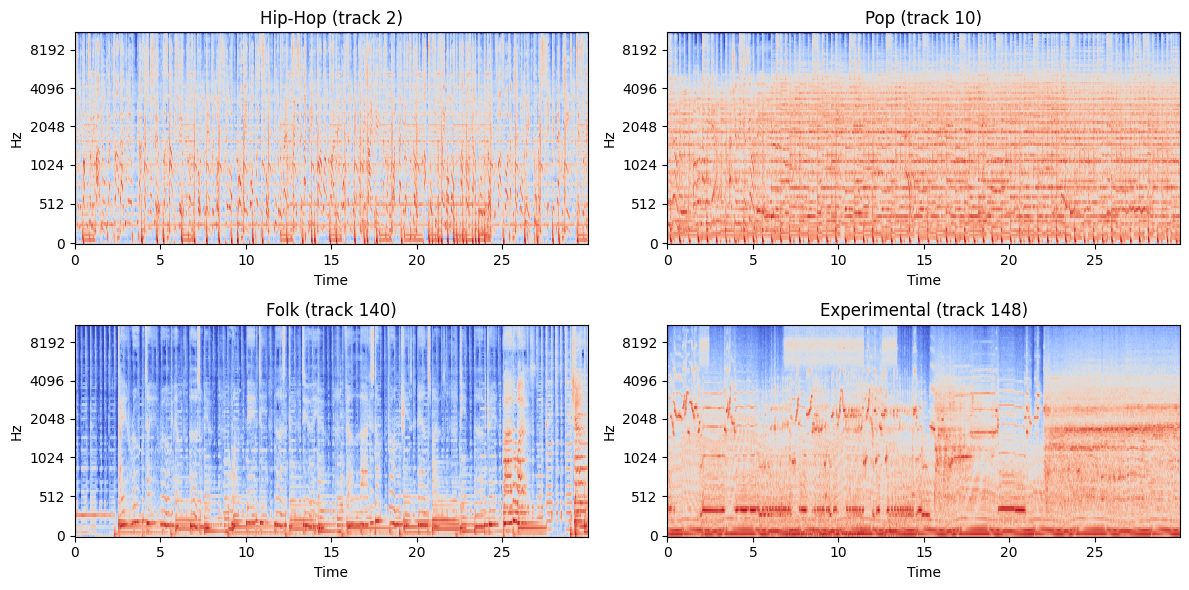

In [9]:
mels = np.load(MEL_PATH, mmap_mode="r")
examples = splits.groupby("genre").head(1).head(4)
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (row, rec) in zip(axes.ravel(), examples.iterrows()):
    librosa.display.specshow(mels[row].astype(np.float32), sr=SR, hop_length=HOP_LENGTH,
                             x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(f"{rec.genre} (track {rec.track_id})")
fig.tight_layout()
plt.show()

## 5. Normalisation and data loaders

Each mel band is standardised with a mean and standard deviation computed on the **training split
only**. The same statistics are applied to validation and test data and saved with the model.

In [10]:
split_rows = {s: np.flatnonzero(splits["split"].to_numpy() == s) for s in ("train", "val", "test")}
labels = splits["genre"].map(label_of).to_numpy()

band_sum = np.zeros(N_MELS)
band_sq = np.zeros(N_MELS)
for i in range(0, len(split_rows["train"]), 512):
    block = mels[split_rows["train"][i:i + 512]].astype(np.float64)
    band_sum += block.sum(axis=(0, 2))
    band_sq += (block ** 2).sum(axis=(0, 2))
count = len(split_rows["train"]) * N_FRAMES
MEL_MEAN = (band_sum / count).astype(np.float32)
MEL_STD = np.sqrt(band_sq / count - (band_sum / count) ** 2).astype(np.float32) + 1e-6
del mels


class MelDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows
        self.mels = None  # opened lazily so each DataLoader worker has its own memmap

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        if self.mels is None:
            self.mels = np.load(MEL_PATH, mmap_mode="r")
        r = self.rows[i]
        x = (self.mels[r].astype(np.float32) - MEL_MEAN[:, None]) / MEL_STD[:, None]
        return torch.from_numpy(x).unsqueeze(0), int(labels[r])


def make_loader(split, shuffle):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(MelDataset(split_rows[split]), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=device.type == "cuda", generator=g,
                      worker_init_fn=lambda w: np.random.seed(SEED + w))


train_loader = make_loader("train", shuffle=True)
val_loader = make_loader("val", shuffle=False)
test_loader = make_loader("test", shuffle=False)
print({s: len(r) for s, r in split_rows.items()})

{'train': 5595, 'val': 1599, 'test': 800}


## 6. C-RNN model

1. **Convolutional front end:** 3 blocks of `Conv2d → BatchNorm → ReLU → MaxPool → Dropout`
   learn local time-frequency patterns.
2. **Recurrent layers:** the conv output is flattened over channels × frequency at each time step
   and fed to a GRU, which models how the music evolves over time.
3. **Per-timestep predictions:** a linear layer produces genre logits at every timestep.
4. **Mean aggregation:** the per-timestep logits are averaged to give the clip-level prediction.

In [11]:
class CRNN(nn.Module):
    def __init__(self, n_mels, n_classes, conv_channels=CONV_CHANNELS, pool_sizes=POOL_SIZES,
                 rnn_hidden=RNN_HIDDEN, rnn_layers=RNN_LAYERS, dropout=DROPOUT):
        super().__init__()
        blocks, in_ch, freq = [], 1, n_mels
        for out_ch, pool in zip(conv_channels, pool_sizes):
            blocks += [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
                       nn.BatchNorm2d(out_ch),
                       nn.ReLU(inplace=True),
                       nn.MaxPool2d(pool),
                       nn.Dropout(dropout)]
            in_ch, freq = out_ch, freq // pool[0]
        self.conv = nn.Sequential(*blocks)
        self.rnn = nn.GRU(in_ch * freq, rnn_hidden, num_layers=rnn_layers, batch_first=True,
                          dropout=dropout if rnn_layers > 1 else 0.0)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(rnn_hidden, n_classes))

    def forward(self, x, return_timesteps=False):
        z = self.conv(x)                                  # (B, C, F, T)
        z = z.permute(0, 3, 1, 2).flatten(2)              # (B, T, C*F)
        z, _ = self.rnn(z)                                # (B, T, H)
        step_logits = self.classifier(z)                  # (B, T, n_classes)
        logits = step_logits.mean(dim=1)                  # mean over timesteps
        return (logits, step_logits) if return_timesteps else logits


model = CRNN(N_MELS, len(CLASS_NAMES)).to(device)
with torch.no_grad():
    out, steps = model(torch.zeros(2, 1, N_MELS, N_FRAMES, device=device), return_timesteps=True)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,} | "
      f"clip logits {tuple(out.shape)} | per-timestep logits {tuple(steps.shape)}")

CRNN(
  (conv): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (4): Dropout(p=0.3, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=(4, 2), stride=(4, 2), padding=0, dilation=1, ceil_mode=False)
    (9): Dropout(p=0.3, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=(4, 2), stride=(4, 2), padding=0, dilation=1, ceil_mode=False)
    (14): Dropout(p=0.3, inplac

## 7. Training

Cross-entropy loss and Adam. After each epoch the model is evaluated on the validation split; the
checkpoint with the best validation accuracy is saved, the learning rate is halved when validation
loss plateaus, and training stops early if validation accuracy stops improving. The test split is
not used here.

In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5,
                                                       patience=LR_PATIENCE)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
CHECKPOINT_PATH = MODELS_DIR / "crnn_best.pt"


def run_epoch(loader, train):
    model.train(train)
    total_loss, preds, targets = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y)
            preds.append(logits.argmax(1).cpu())
            targets.append(y.cpu())
    preds, targets = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    return total_loss / len(targets), float((preds == targets).mean()), preds, targets


def save_checkpoint(epoch, val_acc):
    torch.save({
        "model_state": model.state_dict(),
        "epoch": epoch,
        "val_accuracy": val_acc,
        "class_names": CLASS_NAMES,
        "mel_mean": MEL_MEAN,
        "mel_std": MEL_STD,
        "config": {"sr": SR, "clip_seconds": CLIP_SECONDS, "n_fft": N_FFT, "hop_length": HOP_LENGTH,
                   "n_mels": N_MELS, "conv_channels": CONV_CHANNELS, "pool_sizes": POOL_SIZES,
                   "rnn_hidden": RNN_HIDDEN, "rnn_layers": RNN_LAYERS, "dropout": DROPOUT},
        "splits_sha256": SPLITS_SHA256,
    }, CHECKPOINT_PATH)

In [13]:
history, best_val_acc, epochs_without_improvement = [], -1.0, 0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc, _, _ = run_epoch(train_loader, train=True)
    val_loss, val_acc, _, _ = run_epoch(val_loader, train=False)
    scheduler.step(val_loss)
    lr = optimizer.param_groups[0]["lr"]
    history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                    "val_loss": val_loss, "val_acc": val_acc, "lr": lr})
    pd.DataFrame(history).to_csv(RESULTS_DIR / "training_history.csv", index=False)

    improved = val_acc > best_val_acc
    if improved:
        best_val_acc, epochs_without_improvement = val_acc, 0
        save_checkpoint(epoch, val_acc)
    else:
        epochs_without_improvement += 1
    print(f"epoch {epoch:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f} | lr {lr:.1e} | "
          f"{time.time() - t0:.0f}s{'  *best*' if improved else ''}")
    if epochs_without_improvement >= EARLY_STOP_PATIENCE:
        print(f"Early stopping: no validation improvement for {EARLY_STOP_PATIENCE} epochs.")
        break

print(f"Best validation accuracy: {best_val_acc:.4f}")

epoch  1 | train loss 1.7068 acc 0.3546 | val loss 1.5680 acc 0.4184 | lr 1.0e-03 | 25s  *best*
epoch  2 | train loss 1.4937 acc 0.4593 | val loss 1.4293 acc 0.4816 | lr 1.0e-03 | 23s  *best*
epoch  3 | train loss 1.3811 acc 0.5092 | val loss 1.4538 acc 0.4822 | lr 1.0e-03 | 23s  *best*
epoch  4 | train loss 1.3201 acc 0.5369 | val loss 1.6279 acc 0.4490 | lr 1.0e-03 | 23s
epoch  5 | train loss 1.2693 acc 0.5542 | val loss 1.3747 acc 0.5103 | lr 1.0e-03 | 24s  *best*
epoch  6 | train loss 1.2155 acc 0.5669 | val loss 1.2810 acc 0.5572 | lr 1.0e-03 | 23s  *best*
epoch  7 | train loss 1.1843 acc 0.5862 | val loss 1.2682 acc 0.5710 | lr 1.0e-03 | 24s  *best*
epoch  8 | train loss 1.1540 acc 0.5959 | val loss 1.2445 acc 0.5754 | lr 1.0e-03 | 24s  *best*
epoch  9 | train loss 1.1237 acc 0.6116 | val loss 1.1934 acc 0.5910 | lr 1.0e-03 | 24s  *best*
epoch 10 | train loss 1.0955 acc 0.6204 | val loss 1.2953 acc 0.5722 | lr 1.0e-03 | 24s
epoch 11 | train loss 1.0743 acc 0.6291 | val loss 1.271

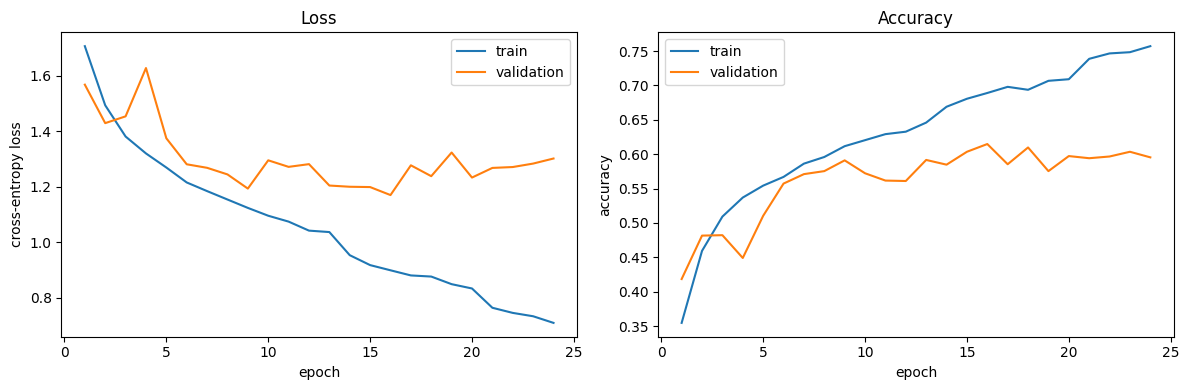

In [14]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], label="validation")
axes[0].set(xlabel="epoch", ylabel="cross-entropy loss", title="Loss")
axes[1].plot(hist["epoch"], hist["train_acc"], label="train")
axes[1].plot(hist["epoch"], hist["val_acc"], label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_curves.png", dpi=150)
plt.show()

## 8. Final test evaluation

The best checkpoint (by validation accuracy) is reloaded and evaluated once on the test split with
the same metrics as the MLP and SVM.

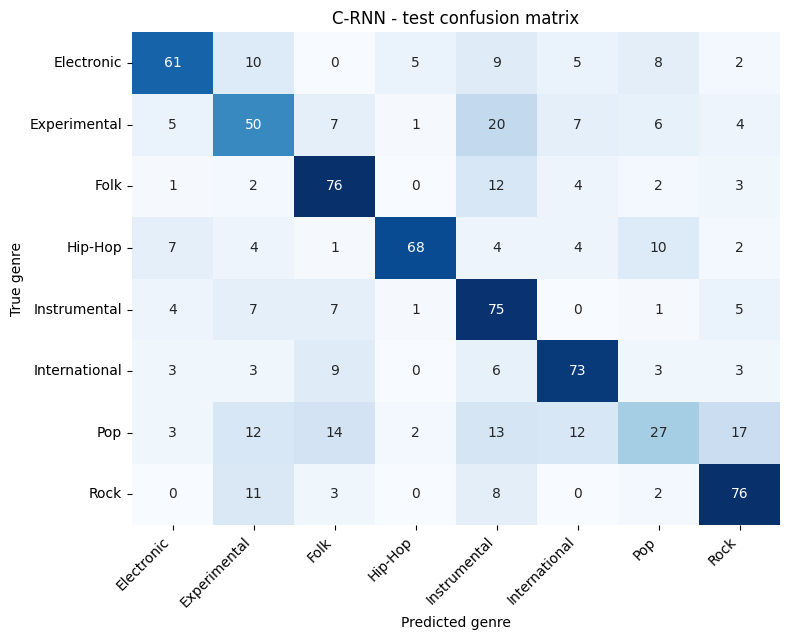

               precision  recall  f1-score  support
Electronic         0.726   0.610     0.663  100.000
Experimental       0.505   0.500     0.503  100.000
Folk               0.650   0.760     0.700  100.000
Hip-Hop            0.883   0.680     0.768  100.000
Instrumental       0.510   0.750     0.607  100.000
International      0.695   0.730     0.712  100.000
Pop                0.458   0.270     0.340  100.000
Rock               0.679   0.760     0.717  100.000
accuracy           0.632   0.632     0.632    0.632
macro avg          0.638   0.632     0.626  800.000
weighted avg       0.638   0.632     0.626  800.000


,C-RNN
val_accuracy,0.6148
test_accuracy,0.6325
precision_macro,0.6382
recall_macro,0.6325
f1_macro,0.6263


In [15]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state"])
test_loss, test_acc, y_pred, y_true = run_epoch(test_loader, train=False)

metrics = compute_metrics(y_true, y_pred, CLASS_NAMES)
metrics.update({"val_accuracy": checkpoint["val_accuracy"], "best_epoch": checkpoint["epoch"],
                "test_loss": test_loss})

plot_confusion_matrix(np.array(metrics["confusion_matrix"]), CLASS_NAMES,
                      "C-RNN - test confusion matrix", RESULTS_DIR / "crnn_confusion_matrix.png")
plt.show()
print(pd.DataFrame(metrics["per_class"]).T.round(3))

test_ids = splits["track_id"].to_numpy()[split_rows["test"]]
pd.DataFrame({"track_id": test_ids,
              "true_genre": [CLASS_NAMES[i] for i in y_true],
              "crnn_pred": [CLASS_NAMES[i] for i in y_pred]}).to_csv(
    RESULTS_DIR / "test_predictions.csv", index=False)

save_json({
    "models": {"crnn": metrics},
    "class_names": CLASS_NAMES,
    "split_counts": splits["split"].value_counts().to_dict(),
    "splits_sha256": SPLITS_SHA256,
    "seed": SEED,
    "device": str(device),
    "torch_version": torch.__version__,
    "config": checkpoint["config"],
    "training": {"batch_size": BATCH_SIZE, "max_epochs": EPOCHS, "epochs_run": len(history),
                 "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY},
}, RESULTS_DIR / "metrics.json")

pd.Series({k: metrics[k] for k in
           ["val_accuracy", "accuracy", "precision_macro", "recall_macro", "f1_macro"]},
          name="C-RNN").rename({"accuracy": "test_accuracy"}).round(4).to_frame()

## 9. Comparison with the paper

`Paper (reference)` is copied from the paper (the poster reports 65.32%); `This run` is computed above.

In [16]:
PAPER_REFERENCE = 0.6523

comparison = pd.DataFrame({
    "Model": ["C-RNN"],
    "Paper (reference)": [PAPER_REFERENCE],
    "This run (test accuracy)": [metrics["accuracy"]],
})
comparison["Difference"] = comparison["This run (test accuracy)"] - comparison["Paper (reference)"]
comparison.to_csv(RESULTS_DIR / "comparison_with_paper.csv", index=False)
comparison.style.format({c: "{:.2%}" for c in comparison.columns if c != "Model"})

,Model,Paper (reference),This run (test accuracy),Difference
0,C-RNN,65.23%,63.25%,-1.98%


## Notes and limitations

- **Inferred architecture:** layer sizes, pooling, RNN type and size, spectrogram parameters and
  training settings are our choices (see the table at the top), not values from the paper.
- **Split:** the paper's exact split is not published. All models here share our stratified
  70/20/10 split (`data/splits.csv`), so the C-RNN and baselines are directly comparable to each
  other, but not on exactly the same test tracks as the paper.
- **Non-determinism:** seeds are fixed, but cuDNN GRU/convolution kernels are not fully
  deterministic, so repeated GPU runs can differ slightly.
- **Saved outputs:** `results/crnn/` (metrics, training history and curves, confusion matrix, test
  predictions) and `models/crnn_best.pt` (weights, normalisation statistics and configuration).